<a href="https://colab.research.google.com/github/silvatria/pembelajaran-mesin-254107023001/blob/main/JS08_TL01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# 1. Library & Load Dataset

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

In [4]:
# 2. Preprocessing (Scaling Fitur)

# Memilih variabel/fitur yang digunakan untuk klasterisasi
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']]

# Standardisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
# 3. Pembuatan Model & Evaluasi (Silhouette Score & DBI)

# Membuat model Agglomerative Clustering
model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Cluster'] = model.fit_predict(X_scaled)

# Menghitung Silhouette Score dan Davies-Bouldin Index (DBI)
sil = silhouette_score(X_scaled, df['Cluster'])
dbi = davies_bouldin_score(X_scaled, df['Cluster'])

print(f"Silhouette Score: {sil:.4f}")  # Hasil: 0.5148
print(f"Davies-Bouldin Index (DBI): {dbi:.4f}")  # Hasil: 0.6810

Silhouette Score: 0.5148
Davies-Bouldin Index (DBI): 0.6810


Silhouette Score : 0.5148
Davies-Bouldin Index (DBI) : 0.6810


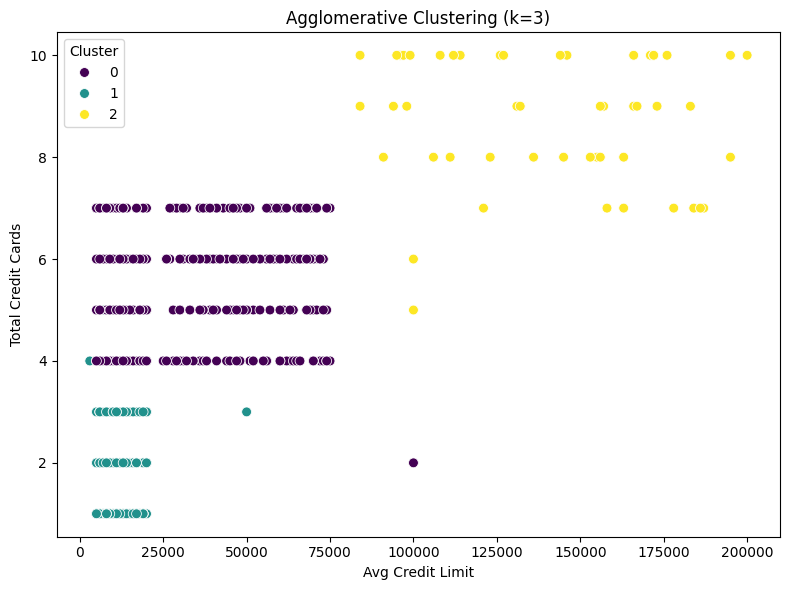

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# 2. Preprocessing & Scaling seluruh fitur
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Model Agglomerative Clustering (k=3)
model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Cluster'] = model.fit_predict(X_scaled)

# 4. Hitung & Print Nilai Evaluasi (Silhouette Score & DBI)
sil = silhouette_score(X_scaled, df['Cluster'])
dbi = davies_bouldin_score(X_scaled, df['Cluster'])

print(f"Silhouette Score : {sil:.4f}")
print(f"Davies-Bouldin Index (DBI) : {dbi:.4f}")

# 5. Visualisasi Scatterplot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='viridis',
    s=50
)
plt.title('Agglomerative Clustering (k=3)')
plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()